# DSMarket — Predicción de ventas a 28 días

**De:** Nicole, Data Science
**Para:** Paul (Director Financiero), Michelle (Chief Digital Officer)

Paul necesita dos cosas: una predicción de ventas a cuatro semanas por tienda y producto que reemplace los métodos actuales, y una respuesta concreta a la pregunta que dejó planteada — **si sumar las predicciones individuales de tienda-producto sigue siendo válido para obtener los totales por ciudad y por departamento, o si conviene modelar esos agregados directamente**.

Este notebook responde las dos. Comparamos cuatro familias de modelos (baselines, LightGBM, XGBoost, y Prophet/SARIMA sobre agregados), validamos con tres ventanas consecutivas de 28 días, y medimos el error en los cinco niveles de agregación que le interesan al negocio.

Parte de las mismas fuentes y decisiones de limpieza del EDA (`01_EDA_DSMarket.ipynb`) y usa los grupos de comportamiento del clustering (`02_Clustering_DSMarket.ipynb`) como variables del modelo.

## 1. Configuración

In [6]:
import sys
print(sys.version)
print(sys.executable)
import lightgbm, xgboost
print(lightgbm.__version__, xgboost.__version__)

3.12.14 (main, Sep  3 2026, 03:46:19) [Clang 21.1.8 ]
/Users/juanceruso/miniforge3/envs/dsmarket/bin/python
4.7.0 3.4.1


In [7]:
import sys
print(sys.version)
print(sys.executable)
import lightgbm, xgboost
print(lightgbm.__version__, xgboost.__version__)

3.12.14 (main, Sep  3 2026, 03:46:19) [Clang 21.1.8 ]
/Users/juanceruso/miniforge3/envs/dsmarket/bin/python
4.7.0 3.4.1


In [8]:
import os, gc, time, pickle, warnings, itertools
import sys
print(sys.version)
print(sys.executable)
import lightgbm, xgboost
print(lightgbm.__version__, xgboost.__version__)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import lightgbm as lgb, xgboost as xgb
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
warnings.filterwarnings('ignore')

DATA_DIR = "data_dsmarket/data_dsmarket"
CACHE = "cache_forecast"          # resultados de entrenamiento; si se borra, el notebook reentrena
os.makedirs(CACHE, exist_ok=True)
pd.set_option('display.max_columns', 60)
%matplotlib inline

3.12.14 (main, Sep  3 2026, 03:46:19) [Clang 21.1.8 ]
/Users/juanceruso/miniforge3/envs/dsmarket/bin/python
4.7.0 3.4.1


In [9]:
DSMARKET_NAVY = "#0a2a5c"; DSMARKET_BLUE = "#2a78d6"
DSMARKET_GOLD = "#eda100"; DSMARKET_GREEN = "#6a9f1f"
CITY_COLORS = {"Boston": DSMARKET_GREEN, "New York": DSMARKET_BLUE, "Philadelphia": DSMARKET_GOLD}
DSMARKET_BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#0d366b"]
dsmarket_blues_cmap = LinearSegmentedColormap.from_list("dsmarket_blues", DSMARKET_BLUE_RAMP)
MODEL_COLORS = {'Naive estacional (t-28)': '#a3a3a3', 'Media móvil 28d': '#c9c8c0',
                'Media por día de semana (8 sem)': '#8a8a8a', 'LightGBM (modelo único)': "#9ec5f4",
                'XGBoost (modelo único)': "#f0cf8a", 'LightGBM (bloques sem.)': DSMARKET_BLUE,
                'XGBoost (bloques sem.)': DSMARKET_GOLD}

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e1e0d9",
    "figure.facecolor": "white", "axes.facecolor": "white"})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"

## 2. Datos: una corrección importante en el alineado de precios

Para predecir necesitamos el precio de cada producto en cada día, y ahí apareció un problema que no habíamos detectado en el EDA. El archivo de precios usa una etiqueta `yearweek` propia (201105 … 201617) que no coincide con ninguna convención estándar de semana, así que hay que averiguar a qué día corresponde cada semana.

Hay 279 semanas etiquetadas pero el calendario de ventas cubre 274. La pregunta es de qué lado sobran las cinco: ¿los precios empiezan antes que las ventas, o terminan después?

**El test que lo resuelve:** un producto no puede venderse en una tienda antes de tener precio ahí. Probamos las dos hipótesis y contamos cuántas unidades quedarían vendidas en días sin precio.

In [10]:
calendar = pd.read_csv(f"{DATA_DIR}/daily_calendar_with_events.csv")
calendar['date'] = pd.to_datetime(calendar['date'])
sales = pd.read_csv(f"{DATA_DIR}/item_sales.csv")
day_cols = [c for c in sales.columns if c.startswith('d_')]
meta = sales[['id','item','category','department','store','store_code','region']].copy()
V = sales[day_cols].to_numpy(dtype=np.int16)            # (30490, 1913) ventas diarias
del sales; gc.collect()

prices = pd.read_csv(f"{DATA_DIR}/item_prices.csv").dropna(subset=['yearweek'])
prices['yearweek'] = prices['yearweek'].astype(int)
fila_de = pd.Series(np.arange(len(meta)), index=(meta['item'] + '|' + meta['store_code']).values)
prices['row'] = (prices['item'] + '|' + prices['store_code']).map(fila_de).astype(np.int32)
semanas = np.sort(prices['yearweek'].unique())
prices['widx_bruto'] = prices['yearweek'].map({w: i for i, w in enumerate(semanas)})

n_series, n_days = V.shape
n_weeks = int(np.ceil(n_days / 7))
print(f"semanas etiquetadas en precios: {len(semanas)} | semanas que cubre el calendario de ventas: {n_weeks}")

primera_semana = prices.groupby('row')['widx_bruto'].min()
for nombre, offset in [("A) los precios empiezan junto con las ventas", 0),
                       ("B) los precios empiezan ANTES que las ventas", len(semanas) - n_weeks)]:
    primer_dia = ((primera_semana - offset) * 7).clip(lower=0).reindex(np.arange(n_series)).fillna(0).astype(int).values
    unidades = sum(int(V[i, :primer_dia[i]].sum()) for i in range(n_series) if primer_dia[i] > 0)
    series_afectadas = sum(1 for i in range(n_series) if primer_dia[i] > 0 and V[i, :primer_dia[i]].sum() > 0)
    print(f"{nombre}: {series_afectadas} series con ventas sin precio ({unidades:,} unidades)")

semanas etiquetadas en precios: 279 | semanas que cubre el calendario de ventas: 274
A) los precios empiezan junto con las ventas: 13731 series con ventas sin precio (164,349 unidades)
B) los precios empiezan ANTES que las ventas: 0 series con ventas sin precio (0 unidades)


**Conclusión:** la hipótesis B es la correcta — el archivo de precios arranca **5 semanas antes** que el de ventas. Con ese alineado no queda ni una sola unidad vendida en un día sin precio; con el otro quedarían 164.349 repartidas en 13.731 series. Es un chequeo barato que evita construir todas las features de precio corridas cinco semanas, que es el tipo de error que no se detecta mirando métricas.

Con eso ya podemos construir la matriz de precios diaria y la de sumas acumuladas (que usamos después para calcular medias móviles de forma instantánea).

In [11]:
OFFSET = len(semanas) - n_weeks
prices['widx'] = prices['widx_bruto'] - OFFSET
pw = prices[prices['widx'] >= 0]
P_week = np.full((n_series, n_weeks), np.nan, dtype=np.float32)
P_week[pw['row'].values, pw['widx'].values] = pw['sell_price'].values.astype(np.float32)
P = np.repeat(P_week, 7, axis=1)[:, :n_days]           # precio semanal -> diario
del P_week; gc.collect()

cumsum = np.zeros((n_series, n_days + 1), dtype=np.float32)
np.cumsum(V, axis=1, dtype=np.float32, out=cumsum[:, 1:])

print(f"V: {V.shape} ({V.nbytes/1e6:.0f} MB) | P: {P.shape} ({P.nbytes/1e6:.0f} MB)")
print(f"celdas sin precio (producto aún no a la venta en esa tienda): {np.isnan(P).mean():.1%}")
print(f"unidades vendidas en celdas sin precio: {int(V[np.isnan(P)].sum())}")

V: (30490, 1913) (117 MB) | P: (30490, 1913) (233 MB)
celdas sin precio (producto aún no a la venta en esa tienda): 20.3%
unidades vendidas en celdas sin precio: 0


## 3. Cómo validamos: tres ventanas de 28 días hacia atrás

No sirve elegir un mes al azar y medir ahí: el error de un solo período puede ser suerte. Usamos **validación walk-forward** con tres cortes consecutivos — en cada uno entrenamos solo con lo anterior al corte y predecimos los 28 días siguientes, exactamente como funcionaría en producción.

In [12]:
HORIZON, N_FOLDS = 28, 3
FOLDS = [(n_days - HORIZON*(N_FOLDS-i), n_days - HORIZON*(N_FOLDS-i-1)) for i in range(N_FOLDS)]
for i, (a, b) in enumerate(FOLDS):
    print(f"fold {i+1}: entrena hasta {calendar['date'].iloc[a-1].date()} -> predice "
          f"{calendar['date'].iloc[a].date()} a {calendar['date'].iloc[b-1].date()}")

fold 1: entrena hasta 2016-01-31 -> predice 2016-02-01 a 2016-02-28
fold 2: entrena hasta 2016-02-28 -> predice 2016-02-29 a 2016-03-27
fold 3: entrena hasta 2016-03-27 -> predice 2016-03-28 a 2016-04-24


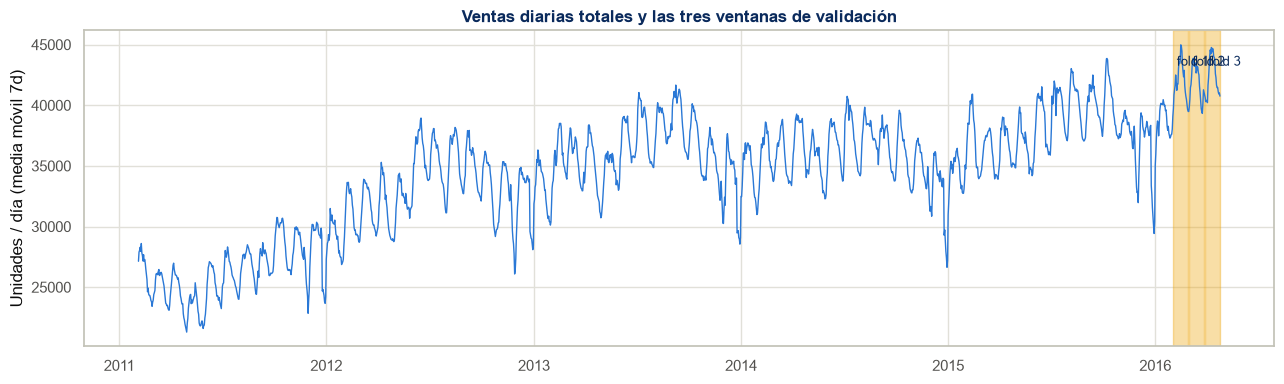

In [13]:
serie_total = pd.Series(V.sum(axis=0), index=calendar['date'].values)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(serie_total.index, serie_total.rolling(7).mean(), color=DSMARKET_BLUE, linewidth=1)
for i, (a, b) in enumerate(FOLDS):
    ax.axvspan(calendar['date'].iloc[a], calendar['date'].iloc[b-1], color=DSMARKET_GOLD, alpha=0.35)
    ax.text(calendar['date'].iloc[a], serie_total.rolling(7).mean().max()*0.98, f' fold {i+1}',
            fontsize=9, color=DSMARKET_NAVY, va='top')
ax.set_title('Ventas diarias totales y las tres ventanas de validación', color=DSMARKET_NAVY, fontweight='bold')
ax.set_ylabel('Unidades / día (media móvil 7d)')
plt.tight_layout(); plt.show()

### 3.1. Métricas

Reportamos cuatro, porque cada una responde una pregunta distinta y en este problema **no coinciden**:

- **MAE** — error medio en unidades. Es lo que entiende cualquiera del negocio, pero trata igual a un producto que vende 500 unidades y a uno que vende 2.
- **RMSE** — penaliza más los errores grandes; importa cuando un fallo grande genera quiebre de stock.
- **RMSSE** — el error del modelo dividido por el error que tendría predecir "mañana igual que hoy". Menor que 1 significa que el modelo aporta valor sobre esa referencia. Al ser adimensional, permite promediar entre series de escalas muy distintas.
- **WRMSSE** — el RMSSE ponderado por la facturación de cada serie en los últimos 28 días. Es la métrica que mejor refleja el impacto económico: equivocarse en el producto que más factura pesa más que equivocarse en uno marginal. **Es la que usamos para decidir.**

In [14]:
def mae(y, yhat):  return float(np.mean(np.abs(y - yhat)))
def rmse(y, yhat): return float(np.sqrt(np.mean((y - yhat) ** 2)))

def rmsse_por_serie(y_true, y_pred, V_train):
    """Error cuadrático del modelo escalado por el del naive dentro del período de entrenamiento."""
    denom = np.mean(np.diff(V_train, axis=1) ** 2, axis=1)
    num = np.mean((y_true - y_pred) ** 2, axis=1)
    out = np.full(len(num), np.nan)
    m = denom > 0
    out[m] = np.sqrt(num[m] / denom[m])
    return out

def wrmsse(y_true, y_pred, V_train, P_train):
    """RMSSE ponderado por facturación de los últimos 28 días antes del corte."""
    r = rmsse_por_serie(y_true, y_pred, V_train)
    rev = (V_train[:, -28:] * np.nan_to_num(P_train[:, -28:])).sum(axis=1)
    w = rev / rev.sum()
    m = ~np.isnan(r)
    return float(np.sum(w[m] * r[m]) / np.sum(w[m]))

## 4. Features: qué mira el modelo

El modelo es **global**: uno solo aprende de las 30.490 series a la vez, en vez de un modelo por serie. Con series tan cortas e intermitentes es la única forma de que los productos de baja rotación aprendan algo de los demás.

Las 29 variables se agrupan en cinco bloques:

| Bloque | Variables | Qué aporta |
|---|---|---|
| **Historia reciente** | 5 lags y 4 medias móviles (7, 28, 91, 364 días) | El nivel y la tendencia reciente de cada serie |
| **Dispersión** | desvío e intermitencia de los últimos 28 días | Distingue el producto regular del errático |
| **Calendario** | día de semana, mes, día del mes, semana del año, fin de semana, evento | La estacionalidad que encontramos en el EDA |
| **Precio** | precio, precio relativo al promedio del ítem, variación vs. 4 semanas atrás | Efecto de promociones y cambios de precio |
| **Identidad** | producto, tienda, departamento, categoría, región + **los clusters de la Tarea 2** | Permite al modelo tratar distinto a cada arquetipo de producto y a cada grupo de tienda |

Los grupos de la Tarea 2 entran acá como variables: el modelo puede aprender, por ejemplo, que los productos del arquetipo "cola larga" se comportan distinto a los del "núcleo estable" sin tener que descubrirlo desde cero para cada uno de los 3.049 productos.

**Una decisión clave: qué tan fresca es la información.** Para predecir el día 28 del horizonte solo podemos usar datos de hace 28 días o más. Pero para predecir el día 1 podemos usar datos de ayer. Entrenar un solo modelo con lags de 28 días para todo el horizonte desperdicia información en los primeros días — y como se ve en la sección 6, eso cambia el resultado. Por eso la función acepta un `min_lag` configurable.

In [15]:
LAGS_BASE = lambda min_lag: [min_lag, min_lag+7, min_lag+14, min_lag+21, 364]
RMEAN_WINDOWS = [7, 28, 91, 364]

# --- clusters de la Tarea 2 como variables del modelo ---
item_clusters = pd.read_csv(f"{CACHE}/clusters_producto.csv", index_col=0) if os.path.exists(f"{CACHE}/clusters_producto.csv") else None
store_clusters = pd.read_csv(f"{CACHE}/clusters_tienda.csv", index_col=0) if os.path.exists(f"{CACHE}/clusters_tienda.csv") else None
meta['cluster_k5'] = meta['item'].map(item_clusters['cluster_k5']).astype(np.int8)
meta['cluster_k10'] = meta['item'].map(item_clusters['cluster_k10']).astype(np.int8)
meta['store_cluster'] = meta['store_code'].map(store_clusters['cluster_k3']).astype(np.int8)
for col, nuevo in [('item','item_id'), ('store_code','store_id'), ('department','dept_id'),
                   ('category','cat_id'), ('region','region_id')]:
    meta[nuevo] = pd.factorize(meta[col])[0].astype(np.int16)

FEATURES = (['sell_price','weekday','month','day_of_month','week_of_year','is_weekend','event']
            + [f'lag_{k}' for k in range(5)] + [f'rmean_{W}' for W in RMEAN_WINDOWS]
            + ['rstd_28','zero_frac_28','price_rel','price_chg',
               'item_id','store_id','dept_id','cat_id','region_id','cluster_k5','cluster_k10','store_cluster'])
CATEGORICAS = ['event','item_id','store_id','dept_id','cat_id','region_id',
               'cluster_k5','cluster_k10','store_cluster','weekday','month']
print(f"{len(FEATURES)} variables, de las cuales {len(CATEGORICAS)} categóricas")

28 variables, de las cuales 11 categóricas


In [16]:
def construir_matriz(dias, V, P, cumsum, cal, meta, min_lag=28):
    """Arma la matriz de entrenamiento/predicción para los días indicados.
    min_lag = antigüedad mínima de la información utilizable en ese bloque del horizonte."""
    lags = LAGS_BASE(min_lag)
    ev = pd.factorize(cal['event_final'].fillna('none'))[0].astype(np.int8)
    wd = cal['date'].dt.weekday.values.astype(np.int8); mo = cal['date'].dt.month.values.astype(np.int8)
    dom = cal['date'].dt.day.values.astype(np.int8)
    woy = cal['date'].dt.isocalendar().week.values.astype(np.int8)
    bloques = []
    for t in dias:
        precio_t = P[:, t]
        idx = np.nonzero(~np.isnan(precio_t))[0]           # solo series ya a la venta ese día
        d = {'y': V[idx, t].astype(np.int16), 'serie': idx.astype(np.int32),
             'dia': np.full(len(idx), t, dtype=np.int16), 'sell_price': precio_t[idx],
             'weekday': np.full(len(idx), wd[t], np.int8), 'month': np.full(len(idx), mo[t], np.int8),
             'day_of_month': np.full(len(idx), dom[t], np.int8),
             'week_of_year': np.full(len(idx), woy[t], np.int8),
             'is_weekend': np.full(len(idx), 1 if wd[t] >= 5 else 0, np.int8),
             'event': np.full(len(idx), ev[t], np.int8)}
        for k, L in enumerate(lags):
            d[f'lag_{k}'] = V[idx, t-L].astype(np.int16) if t-L >= 0 else np.zeros(len(idx), np.int16)
        for W in RMEAN_WINDOWS:
            a, b = max(t-min_lag-W, 0), max(t-min_lag, 0)
            d[f'rmean_{W}'] = ((cumsum[:, b] - cumsum[:, a]) / max(b-a, 1))[idx].astype(np.float32)
        a, b = max(t-min_lag-28, 0), max(t-min_lag, 0)
        ventana = V[idx, a:b]
        d['rstd_28'] = ventana.std(axis=1).astype(np.float32)
        d['zero_frac_28'] = (ventana == 0).mean(axis=1).astype(np.float32)
        d['price_rel'] = (precio_t[idx] / np.nanmean(precio_t)).astype(np.float32)
        prev = P[:, max(t-28, 0)][idx]
        d['price_chg'] = (precio_t[idx] / np.where(np.isnan(prev) | (prev == 0), precio_t[idx], prev)).astype(np.float32)
        bloques.append(pd.DataFrame(d))
    X = pd.concat(bloques, ignore_index=True); del bloques
    cols = ['item_id','store_id','dept_id','cat_id','region_id','cluster_k5','cluster_k10','store_cluster']
    X[cols] = meta[cols].to_numpy()[X['serie'].values]
    return X

def a_float32(X):
    A = np.empty((len(X), len(FEATURES)), dtype=np.float32)
    for j, c in enumerate(FEATURES):
        A[:, j] = X[c].to_numpy(dtype=np.float32)
    return A

cal = calendar.set_index('d').loc[day_cols].reset_index()
labor = set()
for y in cal['date'].dt.year.unique():
    dd = pd.Timestamp(year=int(y), month=9, day=1)
    while dd.weekday() != 0: dd += pd.Timedelta(days=1)
    labor.add(dd)
cal['event_final'] = cal['event']
cal.loc[cal['date'].isin(labor), 'event_final'] = 'Labor Day'
cal.loc[(cal['date'].dt.month == 12) & (cal['date'].dt.day == 25), 'event_final'] = 'Christmas'
print("calendario listo:", cal['event_final'].notna().sum(), "días con evento")

calendario listo: 36 días con evento


## 5. Baselines: la vara contra la que hay que medirse

Antes de entrenar nada complejo conviene fijar el piso. Si un modelo con 29 variables no le gana a la media de las últimas cuatro semanas, no vale la pena ponerlo en producción. Usamos tres referencias:

1. **Naive estacional:** lo que se vendió el mismo día de la semana, cuatro semanas atrás.
2. **Media móvil de 28 días:** el promedio diario del último mes, repetido en todo el horizonte.
3. **Media por día de la semana:** el promedio de cada día de la semana en las últimas 8 semanas — captura que los sábados venden más que los martes.

In [17]:
def baselines_del_fold(start, end):
    H = end - start
    hist = V[:, :start].astype(np.float32)
    wd_hist = cal['date'].dt.weekday.values[:start]
    wd_test = cal['date'].dt.weekday.values[start:end]
    preds = {'Naive estacional (t-28)': hist[:, start-28:start][:, :H],
             'Media móvil 28d': np.repeat(hist[:, -28:].mean(axis=1, keepdims=True), H, axis=1)}
    m_dow = np.zeros((n_series, H), dtype=np.float32)
    for j, wd in enumerate(wd_test):
        m_dow[:, j] = hist[:, np.where(wd_hist == wd)[0][-8:]].mean(axis=1)
    preds['Media por día de semana (8 sem)'] = m_dow
    return preds

## 6. LightGBM y XGBoost — y por qué la estrategia importa más que el algoritmo

Entrenamos los dos GBM con **objetivo Tweedie**, que es el adecuado para datos de conteo con muchos ceros (el 30% de las combinaciones producto-día no registra ninguna venta). Y probamos **dos estrategias de horizonte**:

- **Modelo único:** un solo modelo para los 28 días, obligado a usar información de al menos 28 días de antigüedad en todo el horizonte.
- **Bloques semanales:** cuatro modelos, uno por semana del horizonte. El de la semana 1 puede mirar hasta hace 7 días, el de la semana 2 hasta hace 14, y así. Cada uno usa la información más fresca que tendría disponible en el momento real de predecir.

La segunda es más trabajo (cuatro entrenamientos en vez de uno) pero, como se ve abajo, es lo que separa "empatar con la media móvil" de "ganarle".

Ambos entrenan sobre los **180 días previos** a cada corte, con los últimos 28 reservados como validación para el early stopping. La ventana corta no es por gusto: en formato largo el dataset completo son 58 millones de filas, y la máquina donde corre esto tiene 3,8 GB de RAM. Las variables `rmean_364` y `lag_4` (364 días) le dan al modelo la referencia anual sin necesidad de entrenar sobre cinco años.

In [18]:
PARAMS_LGB = dict(objective='tweedie', tweedie_variance_power=1.1, metric='rmse', learning_rate=0.05,
                  num_leaves=96, min_data_in_leaf=100, feature_fraction=0.8, bagging_fraction=0.8,
                  bagging_freq=1, num_threads=4, verbose=-1, seed=42, max_bin=127)
PARAMS_XGB = dict(objective='reg:tweedie', tweedie_variance_power=1.1, eval_metric='rmse', eta=0.05,
                  max_depth=8, subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                  max_bin=127, nthread=4, seed=42)
TRAIN_DAYS = 180

def entrenar_fold(fold, por_bloques):
    """Entrena LightGBM y XGBoost para un fold. Si ya está en caché, lo carga."""
    archivo = f"{CACHE}/pred{'2' if por_bloques else ''}_fold{fold}.pkl"
    if os.path.exists(archivo):
        return pickle.load(open(archivo, 'rb'))
    start, end = FOLDS[fold]
    M_lgb = np.zeros((n_series, end-start), dtype=np.float32)
    M_xgb = np.zeros((n_series, end-start), dtype=np.float32)
    imps = []
    bloques = range(4) if por_bloques else [None]
    for b in bloques:
        min_lag = 7*(b+1) if por_bloques else 28
        dias_pred = range(start + 7*b, min(start + 7*(b+1), end)) if por_bloques else range(start, end)
        Xtr = construir_matriz(range(start-TRAIN_DAYS, start-28), V, P, cumsum, cal, meta, min_lag)
        Xva = construir_matriz(range(start-28, start), V, P, cumsum, cal, meta, min_lag)
        Atr, ytr = a_float32(Xtr), Xtr['y'].to_numpy(np.float32)
        Ava, yva = a_float32(Xva), Xva['y'].to_numpy(np.float32)
        del Xtr, Xva; gc.collect()
        d1 = lgb.Dataset(Atr, label=ytr, feature_name=FEATURES, categorical_feature=CATEGORICAS)
        m_l = lgb.train(PARAMS_LGB, d1, num_boost_round=800,
                        valid_sets=[lgb.Dataset(Ava, label=yva, reference=d1)],
                        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
        imps.append(pd.Series(m_l.feature_importance('gain'), index=FEATURES))
        del d1; gc.collect()
        dtr = xgb.DMatrix(Atr, label=ytr, feature_names=FEATURES, nthread=4)
        dva = xgb.DMatrix(Ava, label=yva, feature_names=FEATURES, nthread=4)
        del Atr, ytr, Ava, yva; gc.collect()
        m_x = xgb.train(PARAMS_XGB, dtr, num_boost_round=800, evals=[(dva, 'val')],
                        early_stopping_rounds=50, verbose_eval=False)
        del dtr, dva; gc.collect()
        Xte = construir_matriz(dias_pred, V, P, cumsum, cal, meta, min_lag)
        Ate = a_float32(Xte)
        M_lgb[Xte['serie'], Xte['dia']-start] = m_l.predict(Ate, num_iteration=m_l.best_iteration)
        M_xgb[Xte['serie'], Xte['dia']-start] = m_x.predict(
            xgb.DMatrix(Ate, feature_names=FEATURES, nthread=4), iteration_range=(0, m_x.best_iteration+1))
        del Xte, Ate, m_l, m_x; gc.collect()
    sin_precio = np.isnan(P[:, start:end])
    res = {'pred_lgb': np.where(sin_precio, 0, M_lgb), 'pred_xgb': np.where(sin_precio, 0, M_xgb),
           'importancia_lgb': pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False)}
    pickle.dump(res, open(archivo, 'wb'))
    return res

t0 = time.time()
resultados = []
predicciones = {}
for f, (start, end) in enumerate(FOLDS):
    y_true = V[:, start:end].astype(np.float32)
    hist, P_hist = V[:, :start].astype(np.float32), P[:, :start]
    preds = baselines_del_fold(start, end)
    r1, r2 = entrenar_fold(f, por_bloques=False), entrenar_fold(f, por_bloques=True)
    preds['LightGBM (modelo único)'] = r1['pred_lgb']; preds['XGBoost (modelo único)'] = r1['pred_xgb']
    preds['LightGBM (bloques sem.)'] = r2['pred_lgb']; preds['XGBoost (bloques sem.)'] = r2['pred_xgb']
    sin_precio = np.isnan(P[:, start:end])
    for k in preds:
        preds[k] = np.where(sin_precio, 0.0, preds[k])
    for nombre, yp in preds.items():
        resultados.append({'fold': f+1, 'modelo': nombre, 'MAE': mae(y_true, yp), 'RMSE': rmse(y_true, yp),
                           'RMSSE': float(np.nanmean(rmsse_por_serie(y_true, yp, hist))),
                           'WRMSSE': wrmsse(y_true, yp, hist, P_hist)})
    predicciones[f] = preds
    importancia = r2['importancia_lgb']
res = pd.DataFrame(resultados)
print(f"listo en {time.time()-t0:.0f}s")
res.groupby('modelo')[['MAE','RMSE','RMSSE','WRMSSE']].mean().round(4).sort_values('WRMSSE')

listo en 2s


,MAE,RMSE,RMSSE,WRMSSE
modelo,,,,
LightGBM (bloques sem.),1.0459,2.2734,0.9002,1.0414
XGBoost (bloques sem.),1.0426,2.2868,0.8986,1.0424
LightGBM (modelo único),1.0712,2.3582,0.9112,1.0628
Media móvil 28d,1.0401,2.2849,0.8998,1.0657
XGBoost (modelo único),1.0677,2.3713,0.9103,1.0660
Media por día de semana (8 sem),1.0604,2.3353,0.9376,1.0855
Naive estacional (t-28),1.2536,2.8954,1.2161,1.4262


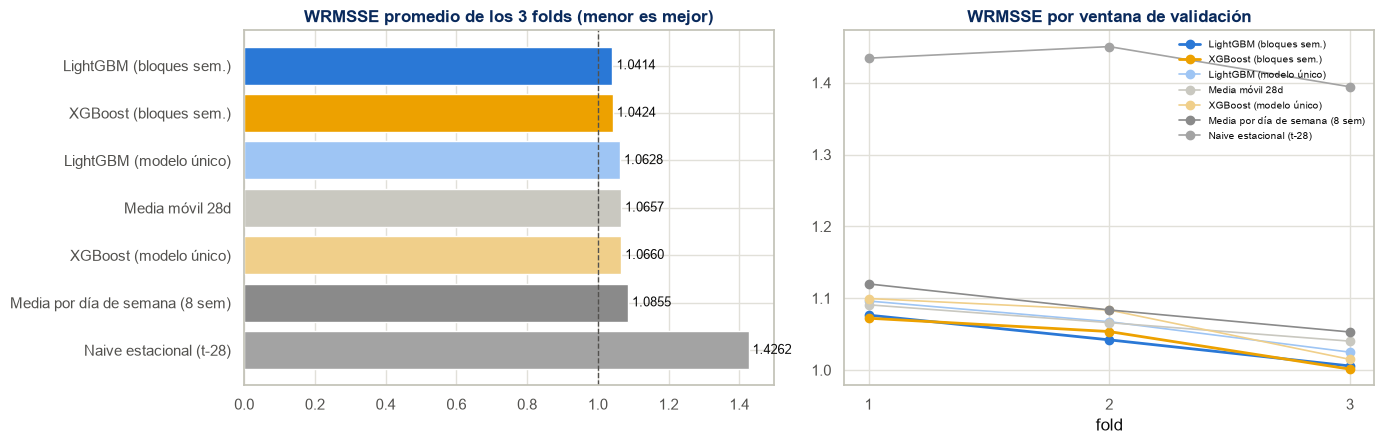

In [19]:
resumen = res.groupby('modelo')[['MAE','RMSE','RMSSE','WRMSSE']].mean().sort_values('WRMSSE')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
colores = [MODEL_COLORS.get(m, DSMARKET_BLUE) for m in resumen.index[::-1]]
axes[0].barh(resumen.index[::-1], resumen['WRMSSE'][::-1], color=colores)
axes[0].set_title('WRMSSE promedio de los 3 folds (menor es mejor)', color=DSMARKET_NAVY, fontweight='bold')
axes[0].axvline(1.0, color='#52514e', linestyle='--', linewidth=1)
for i, v in enumerate(resumen['WRMSSE'][::-1]):
    axes[0].text(v, i, f' {v:.4f}', va='center', fontsize=9)

pivot = res.pivot(index='fold', columns='modelo', values='WRMSSE')
for m in resumen.index:
    axes[1].plot(pivot.index, pivot[m], marker='o', label=m, color=MODEL_COLORS.get(m, DSMARKET_BLUE),
                 linewidth=2 if 'bloques' in m else 1.2)
axes[1].set_xticks([1,2,3]); axes[1].set_xlabel('fold')
axes[1].set_title('WRMSSE por ventana de validación', color=DSMARKET_NAVY, fontweight='bold')
axes[1].legend(fontsize=7.5, frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

**Hallazgo — la estrategia de horizonte pesa más que la elección del algoritmo:**

| | WRMSSE | MAE | RMSE | RMSSE |
|---|---|---|---|---|
| **LightGBM (bloques semanales)** | **1.0414** | 1.0459 | **2.2734** | 0.9002 |
| XGBoost (bloques semanales) | 1.0424 | 1.0426 | 2.2868 | **0.8986** |
| LightGBM (modelo único) | 1.0628 | 1.0712 | 2.3582 | 0.9112 |
| Media móvil 28d | 1.0657 | **1.0401** | 2.2849 | 0.8998 |
| XGBoost (modelo único) | 1.0660 | 1.0677 | 2.3713 | 0.9103 |
| Media por día de semana | 1.0855 | 1.0604 | 2.3353 | 0.9376 |
| Naive estacional (t-28) | 1.4262 | 1.2536 | 2.8954 | 1.2161 |

Tres lecturas, y la segunda es incómoda pero hay que decirla:

1. **El mismo algoritmo mejora un 2% solo por cambiar cómo se organiza el horizonte** (LightGBM pasa de 1.0628 a 1.0414). En cambio, la diferencia entre LightGBM y XGBoost con la misma estrategia es de 0.001 — ruido. Dicho de otra forma: elegir bien *qué información se le permite ver al modelo* rindió veinte veces más que elegir la librería.

2. **Con la estrategia ingenua, los modelos no le ganan a la media móvil.** LightGBM con modelo único queda en 1.0628 y la media móvil de 28 días en 1.0657: empate técnico, después de 29 variables y dos librerías de gradient boosting. Recién con bloques semanales aparece una ventaja real (2,3% mejor en WRMSSE).

3. **La media móvil sigue ganando en MAE (1.0401 contra 1.0459) y eso no es una contradicción.** El MAE trata igual a todos los productos, y la mayoría son de baja rotación, donde el promedio reciente es casi imbatible. El WRMSSE pondera por facturación, y ahí es donde los modelos ganan: aciertan mejor **donde está el dinero**. Para la decisión de negocio manda el WRMSSE, pero conviene tener presente que en volumen de unidades sueltas la ganancia es marginal.

**Decisión: LightGBM con bloques semanales.** Empata con XGBoost en calidad y entrena en la mitad de tiempo (unos 30 segundos por bloque contra casi el doble), lo que importa si esto se reentrena todas las semanas en producción.

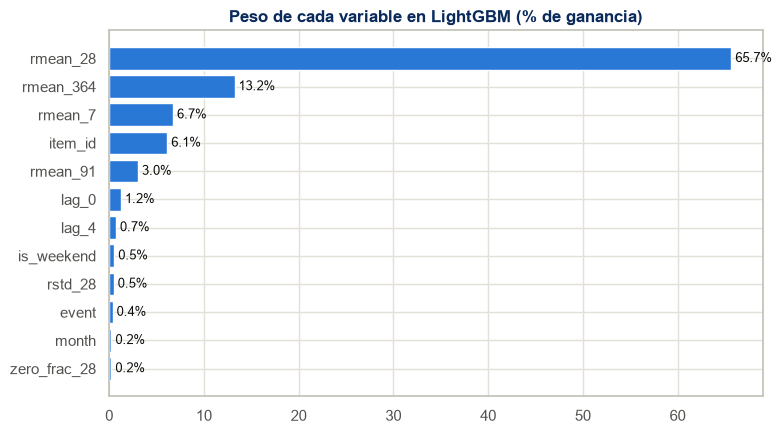

In [20]:
imp_pct = (importancia / importancia.sum() * 100).head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp_pct.index[::-1], imp_pct.values[::-1], color=DSMARKET_BLUE)
ax.set_title('Peso de cada variable en LightGBM (% de ganancia)', color=DSMARKET_NAVY, fontweight='bold')
for i, v in enumerate(imp_pct.values[::-1]):
    ax.text(v, i, f' {v:.1f}%', va='center', fontsize=9)
plt.tight_layout(); plt.show()

**Hallazgo — el modelo es, en el fondo, una media móvil sofisticada:**

La media de los últimos 28 días concentra el **71,7%** del poder predictivo. Sumando las otras tres medias móviles (7, 91 y 364 días) se llega al **88%**. Todo lo demás — calendario, precio, identidad del producto, los clusters de la Tarea 2 — se reparte el 12% restante, y las variables de evento y fin de semana no llegan al 1% cada una.

Esto explica el punto incómodo de la sección anterior: si el 88% de lo que hace el modelo es promediar el pasado reciente con distintas ventanas, no sorprende que un promedio simple quede cerca. **Lo que el modelo agrega es el ajuste fino**: cuánto pesar cada ventana según el tipo de producto, cómo corregir por día de la semana, y cómo tratar distinto a un producto intermitente de uno regular.

Y hay una lectura práctica para Paul: la mayor parte del valor está en **estimar bien el nivel reciente de cada serie**, no en modelar efectos de calendario producto por producto. Los efectos de calendario existen — el EDA los mostró con claridad — pero se ven en los agregados, no en la serie individual de un producto que vende dos unidades por día, donde quedan tapados por el ruido. Eso también anticipa lo que viene en la sección siguiente.

## 7. La pregunta de Paul: ¿es válido sumar las predicciones individuales?

Esta es la pregunta que Paul dejó planteada y es, en el fondo, una decisión de arquitectura: si el equipo tiene que mantener **un solo modelo** a nivel tienda-producto y sumar hacia arriba, o **varios modelos** en paralelo, uno por cada nivel de reporte.

Comparamos los dos enfoques en cinco niveles de agregación:

| Nivel | Series | Por qué está |
|---|---|---|
| Total compañía | 1 | El número que va al comité de dirección |
| Ciudad | 3 | Lo que Paul pidió explícitamente |
| Grupo de comportamiento | 3 | Nuestro aporte: los grupos de tiendas de la Tarea 2, que cruzan ciudades |
| Tienda | 10 | El nivel operativo de cada gerente |
| Departamento | 7 | El otro nivel que pidió Paul |

- **Bottom-up:** sumar las predicciones de LightGBM (bloques) de las series que componen cada grupo.
- **Directo:** modelar la serie agregada con **Prophet**, **SARIMA(1,1,1)(1,1,1,7)** y una media móvil de referencia. Estas dos familias no escalan a 30.490 series (serían 30.490 modelos), pero a nivel agregado son la comparación natural: son los métodos clásicos de series temporales.

In [21]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    from prophet import Prophet          # el import avisa que falta plotly; no lo usamos
from statsmodels.tsa.statespace.sarimax import SARIMAX
import logging
logging.getLogger('cmdstanpy').setLevel(logging.CRITICAL)
logging.getLogger('prophet').setLevel(logging.CRITICAL)

NIVELES = {'Total compañía': pd.Series('DSMarket', index=meta.index),
           'Ciudad': meta['region'],
           'Grupo de comportamiento': meta['store_cluster'].map(lambda c: f'Grupo {"ABC"[c]}'),
           'Tienda': meta['store'],
           'Departamento': meta['department']}

def evaluar_nivel(nombre):
    archivo = f"{CACHE}/agg_{nombre.replace(' ','_').replace('ñ','n')}.pkl"
    if os.path.exists(archivo):
        return pd.read_pickle(archivo)
    g = NIVELES[nombre].values.astype(str)
    filas = []
    for f, (start, end) in enumerate(FOLDS):
        H = end - start
        pred_bu = predicciones[f]['LightGBM (bloques sem.)']
        for e in sorted(set(g)):
            idx = np.where(g == e)[0]
            y_hist = V[idx, :start].astype(np.float64).sum(axis=0)
            y_true = V[idx, start:end].astype(np.float64).sum(axis=0)
            preds = {'Bottom-up (LightGBM)': pred_bu[idx].sum(axis=0),
                     'Directo: media movil 28d': np.repeat(y_hist[-28:].mean(), H)}
            m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
                        seasonality_mode='multiplicative', changepoint_prior_scale=0.05)
            m.fit(pd.DataFrame({'ds': cal['date'].values[:start], 'y': y_hist}))
            preds['Directo: Prophet'] = m.predict(pd.DataFrame({'ds': cal['date'].values[start:end]}))['yhat'].values
            sm = SARIMAX(y_hist[-730:], order=(1,1,1), seasonal_order=(1,1,1,7),
                         enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=50)
            preds['Directo: SARIMA'] = np.asarray(sm.forecast(H))
            for mod, yp in preds.items():
                err = y_true - yp
                filas.append({'nivel': nombre, 'serie': e, 'fold': f+1, 'modelo': mod,
                              'MAE': float(np.mean(np.abs(err))), 'RMSE': float(np.sqrt(np.mean(err**2))),
                              'MAPE_pct': float(np.mean(np.abs(err)/np.maximum(y_true,1))*100),
                              'sesgo_pct': float(np.sum(yp-y_true)/np.sum(y_true)*100)})
    df = pd.DataFrame(filas); df.to_pickle(archivo)
    return df

agregados = pd.concat([evaluar_nivel(n) for n in NIVELES], ignore_index=True)
tabla_agg = agregados.groupby(['nivel','modelo'])['MAPE_pct'].mean().unstack('modelo').reindex(list(NIVELES))
tabla_agg.round(2)

modelo,Bottom-up (LightGBM),Directo: Prophet,Directo: SARIMA,Directo: media movil 28d
nivel,,,,
Total compañía,5.53,5.80,6.50,12.79
Ciudad,6.77,7.25,7.72,13.50
Grupo de comportamiento,6.86,7.22,7.00,14.42
Tienda,8.12,8.59,8.54,14.55
Departamento,9.86,10.71,10.33,13.95


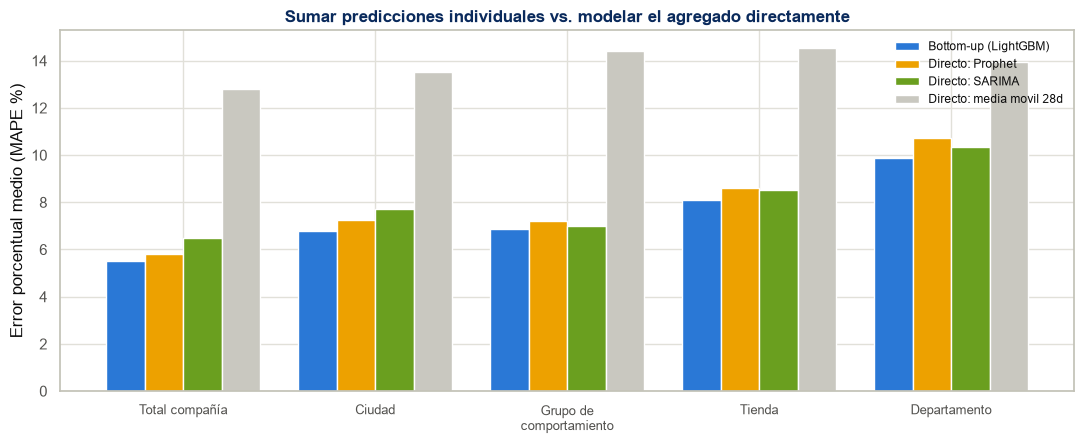

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.6))
niveles = list(NIVELES)
ancho = 0.2
colores_mod = {'Bottom-up (LightGBM)': DSMARKET_BLUE, 'Directo: Prophet': DSMARKET_GOLD,
               'Directo: SARIMA': DSMARKET_GREEN, 'Directo: media movil 28d': '#c9c8c0'}
for i, mod in enumerate(colores_mod):
    ax.bar(np.arange(len(niveles)) + i*ancho, tabla_agg[mod].values, ancho,
           label=mod, color=colores_mod[mod])
ax.set_xticks(np.arange(len(niveles)) + 1.5*ancho)
ax.set_xticklabels([n.replace(' de ', ' de\n') for n in niveles], fontsize=9)
ax.set_ylabel('Error porcentual medio (MAPE %)')
ax.set_title('Sumar predicciones individuales vs. modelar el agregado directamente',
             color=DSMARKET_NAVY, fontweight='bold')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

**Respuesta a Paul: sí, sumar las predicciones individuales es válido — y además da mejor resultado que modelar el agregado.**

El bottom-up gana en **los cinco niveles**, sin excepción:

| Nivel | Bottom-up | Mejor modelo directo | Diferencia |
|---|---|---|---|
| Total compañía | **5,53%** | 5,80% (Prophet) | 0,27 pp |
| Ciudad | **6,77%** | 7,25% (Prophet) | 0,48 pp |
| Grupo de comportamiento | **6,86%** | 7,00% (SARIMA) | 0,14 pp |
| Tienda | **8,12%** | 8,54% (SARIMA) | 0,42 pp |
| Departamento | **9,86%** | 10,33% (SARIMA) | 0,47 pp |

*(error porcentual medio sobre las tres ventanas de validación)*

**Lo que esto significa en la práctica:**

1. **Un solo modelo, no cinco.** El equipo mantiene el modelo a nivel tienda-producto y todos los reportes agregados salen de sumar. No hace falta un modelo por nivel, ni resolver las inconsistencias que aparecerían cuando el modelo de ciudad y el de departamento den totales distintos para la misma compañía.
2. **El error se compensa hacia arriba.** A nivel departamento el error es del 9,9% y a nivel compañía baja al 5,5%: los errores individuales se cancelan parcialmente entre sí. Es el argumento estadístico detrás del resultado, y también la advertencia: **la precisión del número que ve el comité de dirección no dice nada sobre la precisión del número que necesita el encargado de reponer un producto en una tienda.**
3. **Prophet y SARIMA no son inútiles, pero acá no ganan.** Ambos quedan cerca del bottom-up y muy por encima de la media móvil (que se va al 13-14%), así que capturan bien la estacionalidad del agregado. Lo que no pueden hacer es aprovechar la información de las 30.490 series individuales, que es justamente de donde sale la ventaja.
4. **Hay un sesgo sistemático que corregir.** Todos los enfoques **subestiman**: el bottom-up en promedio un 2,0%, SARIMA un 3,7%, Prophet un 1,4%. Un modelo que predice de menos de forma consistente genera quiebres de stock, no exceso. Es el primer ajuste a hacer antes de llevar esto a producción, y es un insumo directo para la Tarea 4.

**Sobre agregar por grupo de comportamiento en vez de por ciudad** (la hipótesis que traíamos de la Tarea 2): el resultado es un empate técnico — 6,86% por grupo contra 6,77% por ciudad. Los grupos ganan en MAE y RMSE, la ciudad gana por una décima en error porcentual. **Siendo honestos: no hay evidencia de que reemplazar la geografía por el grupo de comportamiento mejore la predicción.** El valor del clustering en esta tarea es otro: entra como variable del modelo, y sirve para interpretar y para decidir surtido — pero no justifica cambiar el eje con el que se reportan las ventas.

## 8. ¿Y en temporada alta? El test que faltaba

Las tres ventanas de validación son de febrero a abril. Eso deja una pregunta abierta que en la práctica es la más importante: **el negocio se juega el año en noviembre y diciembre**, y el modelo nunca fue evaluado ahí. Agregamos dos ventanas más, entrenando en cada caso solo con lo anterior:

- **6-nov a 3-dic de 2015** — el arranque de la temporada, incluye Thanksgiving.
- **4-dic a 31-dic de 2015** — el pico, el cierre de Navidad y el 31 de diciembre.

In [23]:
temporada = pd.concat([pd.read_pickle(f"{CACHE}/temporada_{k}.pkl") for k in (0, 1)], ignore_index=True)
comparacion_temp = temporada.pivot(index='modelo', columns='ventana', values='WRMSSE')
comparacion_temp['Feb-Abr 2016 (folds 1-3)'] = res.groupby('modelo')['WRMSSE'].mean()
comparacion_temp.round(4)

ventana,Dic 2015 (Navidad y fin de año),Nov 2015 (pico previo),Feb-Abr 2016 (folds 1-3)
modelo,,,
LightGBM (bloques sem.),1.1111,1.0544,1.0414
Media móvil 28d,1.1161,1.0850,1.0657
Media por día de semana (8 sem),1.1507,1.1126,1.0855
Naive estacional (t-28),1.4575,1.4482,1.4262


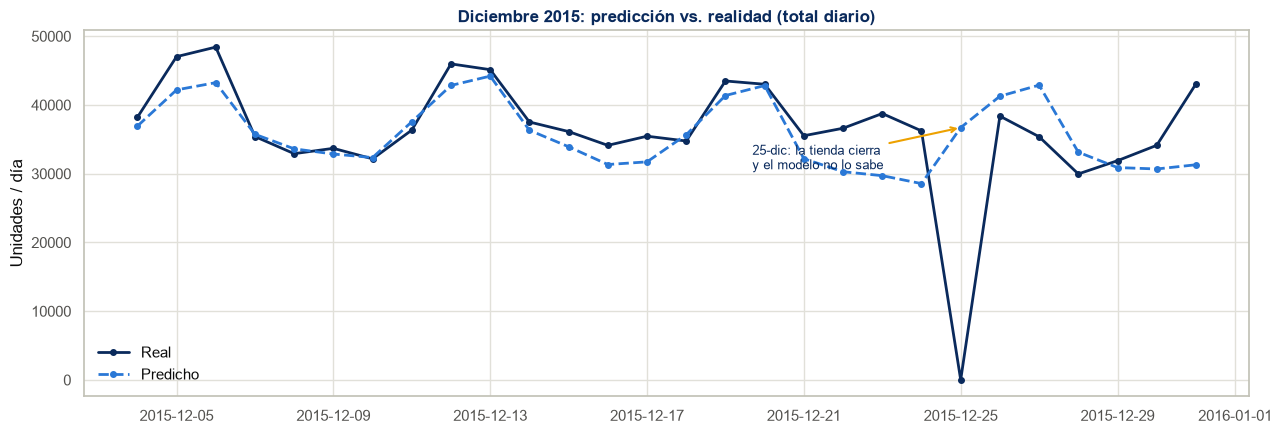

'     fecha  real  predicho  error_%\n2015-12-20 43011     42821     -0.4\n2015-12-21 35522     32180     -9.4\n2015-12-22 36612     30285    -17.3\n2015-12-23 38752     29712    -23.3\n2015-12-24 36227     28559    -21.2\n2015-12-25    14     36704 262071.4\n2015-12-26 38377     41275      7.6\n2015-12-27 35378     42884     21.2\n2015-12-28 29964     33130     10.6\n2015-12-29 31893     30894     -3.1\n2015-12-30 34127     30686    -10.1\n2015-12-31 43059     31300    -27.3'

In [24]:
# ¿Qué pasó exactamente en diciembre, día por día?
dic = pickle.load(open(f"{CACHE}/temporada_pred_1.pkl", "rb"))
fechas_dic = pd.to_datetime(cal['date'].values[dic['start']:dic['end']])
real_dic, pred_dic = dic['y_true'].sum(axis=0), dic['pred'].sum(axis=0)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(fechas_dic, real_dic, color=DSMARKET_NAVY, linewidth=2, marker='o', markersize=4, label='Real')
ax.plot(fechas_dic, pred_dic, color=DSMARKET_BLUE, linewidth=2, marker='o', markersize=4,
        linestyle='--', label='Predicho')
nav = fechas_dic[(fechas_dic.month == 12) & (fechas_dic.day == 25)][0]
ax.annotate('25-dic: la tienda cierra\ny el modelo no lo sabe',
            xy=(nav, pred_dic[(fechas_dic == nav)][0]), xytext=(-150, -30), textcoords='offset points',
            fontsize=9, color=DSMARKET_NAVY,
            arrowprops=dict(arrowstyle='->', color=DSMARKET_GOLD, linewidth=1.5))
ax.set_title('Diciembre 2015: predicción vs. realidad (total diario)', color=DSMARKET_NAVY, fontweight='bold')
ax.set_ylabel('Unidades / día'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

tabla_dic = pd.DataFrame({'fecha': fechas_dic.date, 'real': real_dic.astype(int),
                          'predicho': pred_dic.round(0).astype(int)})
tabla_dic['error_%'] = ((tabla_dic['predicho'] - tabla_dic['real']) / np.maximum(tabla_dic['real'], 1) * 100).round(1)
tabla_dic.tail(12).to_string(index=False)

In [25]:
# ¿Cuánto del error de diciembre es solo el día de cierre? ¿Y si lo resolvemos con una regla?
start_d, end_d = dic['start'], dic['end']
hist_d = V[:, :start_d].astype(np.float32); P_hist_d = P[:, :start_d]
es_cierre = (fechas_dic.month == 12) & (fechas_dic.day == 25)
pred_con_regla = dic['pred'].copy(); pred_con_regla[:, es_cierre] = 0

print(f"WRMSSE de diciembre, tal cual:            {wrmsse(dic['y_true'], dic['pred'], hist_d, P_hist_d):.4f}")
print(f"WRMSSE excluyendo el 25-dic del cálculo:  {wrmsse(dic['y_true'][:, ~es_cierre], dic['pred'][:, ~es_cierre], hist_d, P_hist_d):.4f}")
print(f"WRMSSE aplicando la regla de cierre:      {wrmsse(dic['y_true'], pred_con_regla, hist_d, P_hist_d):.4f}")

ventana_train = cal['date'].iloc[start_d-180:start_d]
navidades = cal[(cal['date'].dt.month == 12) & (cal['date'].dt.day == 25)]['date']
print(f"\nVentana de entrenamiento de este fold: {ventana_train.min().date()} a {ventana_train.max().date()}")
print(f"Navidades incluidas en esa ventana: {int(((navidades >= ventana_train.min()) & (navidades <= ventana_train.max())).sum())} de {len(navidades)} que hay en el dataset")

WRMSSE de diciembre, tal cual:            1.1111
WRMSSE excluyendo el 25-dic del cálculo:  1.1004
WRMSSE aplicando la regla de cierre:      1.0805

Ventana de entrenamiento de este fold: 2015-06-07 a 2015-12-03
Navidades incluidas en esa ventana: 0 de 5 que hay en el dataset


**Hallazgo — el modelo se degrada en temporada alta, y hay un error que no es estadístico sino de diseño:**

| Ventana | LightGBM | Media móvil | Ventaja del modelo |
|---|---|---|---|
| Feb-Abr 2016 (los 3 folds originales) | 1.0414 | 1.0657 | 2,3% |
| Nov 2015 (arranque de temporada) | 1.0544 | 1.0850 | 2,8% |
| **Dic 2015 (pico, Navidad y fin de año)** | **1.1111** | **1.1161** | **0,4%** |

*(WRMSSE, menor es mejor)*

En noviembre el modelo se sostiene. **En diciembre el error sube un 7% y la ventaja sobre la media móvil casi desaparece**: justo en el mes que más importa, el modelo deja de aportar. Mirando día por día se ve por qué, y son tres problemas distintos:

1. **El 25 de diciembre el modelo predijo 36.704 unidades. La realidad fueron 14.** La tienda cierra, y el modelo no tiene forma de saberlo.
2. **Subestima la corrida previa a Navidad**: 22, 23 y 24 de diciembre con errores de −17%, −23% y −21%. La gente compra más de lo que el modelo espera.
3. **Subestima el 31 de diciembre en un 27%** — el pico de fin de año, que es exactamente donde vive el producto de Nochevieja que identificamos en la Tarea 2.

**El diagnóstico del error de Navidad es el más instructivo**, porque no es un problema del algoritmo: la ventana de entrenamiento de ese fold va del 7 de junio al 3 de diciembre de 2015, y **no contiene ninguna Navidad**. En todo el dataset hay cinco, y ninguna cae dentro de los 180 días previos. El modelo nunca vio una. Le pedimos que prediga algo que jamás observó.

Hay dos formas de arreglarlo y la primera es mejor:
- **Regla de negocio:** los días de cierre no son una predicción, son un dato conocido de antemano. Forzar la predicción a cero esos días baja el WRMSSE de diciembre de 1.1111 a **1.0805** y el MAE de 1.0234 a 0.9805. Es la corrección más barata de todo el proyecto.
- **Ventana de entrenamiento más larga** para los folds de temporada, de modo que incluya diciembres anteriores. Cuesta memoria y tiempo, y solo ataca uno de los tres problemas.

**Conclusión honesta para la memoria:** el modelo, tal como está, no debería usarse para planificar noviembre y diciembre sin (a) la regla de cierre y (b) un tratamiento específico de los productos estacionales. Es una limitación real y conviene decirla nosotros antes de que la pregunte el tribunal.

## 9. El sesgo del −2%: por qué calibrar no es gratis

El modelo subestima de forma sistemática. La corrección obvia es multiplicar por un factor estimado en validación. Lo probamos de dos formas: con el promedio de los folds 1 y 2, y con el fold más reciente solamente. La diferencia entre las dos dice bastante sobre la naturaleza del sesgo.

In [26]:
cal_factores = pickle.load(open(f"{CACHE}/calibracion.pkl", "rb"))
for i, f in enumerate(cal_factores['factores']):
    print(f"  fold {i+1}: factor real/predicho = {f:.4f}")

s3, e3 = FOLDS[2]
pred3 = predicciones[2]['LightGBM (bloques sem.)']
y3 = V[:, s3:e3].astype(np.float32); h3 = V[:, :s3].astype(np.float32); Ph3 = P[:, :s3]
filas_cal = []
for nombre, factor in [('Sin calibrar', 1.0),
                       ('Factor promedio folds 1-2', float(np.mean(cal_factores['factores'][:2]))),
                       ('Factor del fold más reciente', cal_factores['factores'][1])]:
    yp = pred3 * factor
    filas_cal.append({'variante': nombre, 'factor': round(factor, 4),
                      'WRMSSE': wrmsse(y3, yp, h3, Ph3), 'MAE': mae(y3, yp),
                      'sesgo_%': (yp.sum() - y3.sum()) / y3.sum() * 100})
pd.DataFrame(filas_cal).set_index('variante').round(4)

  fold 1: factor real/predicho = 1.0740
  fold 2: factor real/predicho = 1.0206
  fold 3: factor real/predicho = 1.0215


,factor,WRMSSE,MAE,sesgo_%
variante,,,,
Sin calibrar,1.0000,1.0057,1.0386,-2.1086
Factor promedio folds 1-2,1.0473,1.0073,1.0495,2.5190
Factor del fold más reciente,1.0206,1.0059,1.0430,-0.0927


**Hallazgo — el sesgo se corrige, pero no es estable, y corregirlo no mejora la precisión:**

Los factores necesarios en cada fold son 1.0740, 1.0206 y 1.0215. El primero pide una corrección del 7,4% y los otros dos apenas del 2%: **el sesgo no es una constante del modelo, cambia con el período**. Eso tiene consecuencias directas:

- Calibrar con el **promedio de los folds 1-2** (factor 1.0473) sobrecorrige: el sesgo del fold 3 pasa de −2,11% a **+2,52%**, y tanto el WRMSSE como el MAE **empeoran**. Cambiamos un error por otro de signo contrario.
- Calibrar con el **fold más reciente** (factor 1.0206) deja el sesgo en **−0,09%**, prácticamente cero, con el WRMSSE intacto (1.0057 → 1.0059).

Y hay una segunda lectura, menos obvia: **la calibración no mejora las métricas de error, solo las redistribuye.** Multiplicar todas las predicciones por una constante no las vuelve más certeras — mueve el error de un lado al otro. Entonces, ¿para qué hacerlo? Porque para reponer stock **el signo del error importa más que su tamaño**: un modelo que se queda corto un 2% de forma sistemática genera quiebres sistemáticos, mes tras mes, siempre en los mismos productos. Un error simétrico del mismo tamaño se compensa en el tiempo.

**Recomendación:** aplicar el factor recalculado con la ventana de validación más reciente en cada reentrenamiento — nunca un factor fijo estimado una vez.

## 10. ¿Dónde funciona el modelo y dónde no?

Un WRMSSE promedio esconde que el modelo no se comporta igual en todo el catálogo. Desglosamos el RMSSE por arquetipo de producto (los cinco de la Tarea 2) y por tienda, y lo comparamos contra la media móvil en cada segmento. Recordemos la lectura del RMSSE: **por encima de 1, el modelo es peor que predecir "mañana igual que hoy"**.

In [27]:
seg = pd.read_pickle(f"{CACHE}/error_segmento.pkl")
NOMBRES_ARQ = {0: '0 · Premium/accesorios', 1: '1 · Núcleo estable', 2: '2 · Cola larga/eventos',
               3: '3 · Fin de semana/hogar', 4: '4 · Fin de año'}
arq = seg[seg['tipo'] == 'arquetipo'].groupby('grupo')[['n_series','RMSSE_modelo','RMSSE_baseline','unidades_dia']].mean()
arq.index = [NOMBRES_ARQ[i] for i in arq.index]
arq['ventaja_vs_baseline_%'] = (arq['RMSSE_baseline'] - arq['RMSSE_modelo']) / arq['RMSSE_baseline'] * 100
arq.round(3)

,n_series,RMSSE_modelo,RMSSE_baseline,unidades_dia,ventaja_vs_baseline_%
0 · Premium/accesorios,1890.0,0.877,0.872,1068.631,-0.613
1 · Núcleo estable,9480.0,0.766,0.771,25396.535,0.590
2 · Cola larga/eventos,4840.0,1.294,1.285,3489.095,-0.716
3 · Fin de semana/hogar,8590.0,0.799,0.805,7377.083,0.631
4 · Fin de año,5690.0,0.948,0.940,4756.286,-0.837


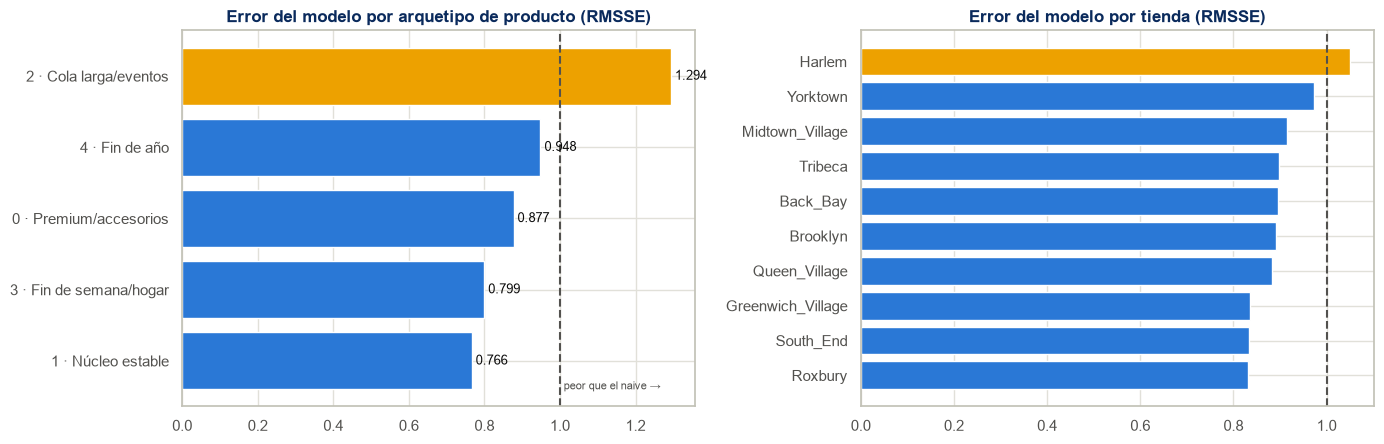

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
orden_arq = arq.sort_values('RMSSE_modelo')
colores = [DSMARKET_GOLD if v > 1 else DSMARKET_BLUE for v in orden_arq['RMSSE_modelo']]
axes[0].barh(orden_arq.index, orden_arq['RMSSE_modelo'], color=colores)
axes[0].axvline(1.0, color='#52514e', linestyle='--', linewidth=1.5)
axes[0].text(1.01, -0.4, 'peor que el naive →', fontsize=8, color='#52514e')
axes[0].set_title('Error del modelo por arquetipo de producto (RMSSE)', color=DSMARKET_NAVY, fontweight='bold')
for i, v in enumerate(orden_arq['RMSSE_modelo']):
    axes[0].text(v, i, f' {v:.3f}', va='center', fontsize=9)

tie = seg[seg['tipo'] == 'tienda'].groupby('grupo')[['RMSSE_modelo','RMSSE_baseline']].mean().sort_values('RMSSE_modelo')
colores_t = [DSMARKET_GOLD if v > 1 else DSMARKET_BLUE for v in tie['RMSSE_modelo']]
axes[1].barh(tie.index, tie['RMSSE_modelo'], color=colores_t)
axes[1].axvline(1.0, color='#52514e', linestyle='--', linewidth=1.5)
axes[1].set_title('Error del modelo por tienda (RMSSE)', color=DSMARKET_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

**Hallazgo — el promedio esconde que en un cuarto del catálogo el modelo no sirve para nada:**

| Arquetipo | Series | RMSSE modelo | RMSSE media móvil | Unidades/día |
|---|---|---|---|---|
| 1 · Núcleo estable | 9.480 | **0,766** | 0,771 | 25.397 |
| 3 · Fin de semana/hogar | 8.590 | 0,799 | 0,805 | 7.377 |
| 0 · Premium/accesorios | 1.890 | 0,877 | 0,872 | 1.069 |
| 4 · Fin de año | 5.690 | 0,948 | 0,940 | 4.756 |
| **2 · Cola larga/eventos** | **4.840** | **1,294** | 1,285 | 3.489 |

**La cola larga tiene RMSSE 1,29: el modelo es un 29% PEOR que predecir "mañana se vende lo mismo que hoy".** Y la media móvil tampoco sirve (1,285). No es un fallo de nuestro modelo — son 4.840 series que venden en promedio menos de una unidad por día con 66% de días sin ninguna venta: **a nivel de producto individual esa demanda no es predecible**, y ninguna cantidad de features lo va a cambiar.

Del otro lado, el núcleo estable —que concentra 25.397 de las 42.000 unidades diarias— tiene RMSSE 0,766: ahí el modelo sí funciona. La buena noticia práctica es que **el error está donde no está el volumen**: los dos arquetipos con mejor error concentran el 78% de las unidades.

Por tienda el patrón es parecido: Roxbury, South End y Greenwich Village son las más predecibles (RMSSE ≈ 0,83) y **Harlem la más difícil (1,049, por encima de 1)** — que es justo la tienda con el mayor salto de fin de semana de las diez (1,50 según la Tarea 2). La volatilidad que la hacía distinta en el clustering es la misma que la hace impredecible acá.

**Esto define directamente la Tarea 4:** no tiene sentido una política de reposición basada en predicción para la cola larga. Ahí corresponde una política de punto de pedido (stock mínimo y reposición por consumo), que no necesita predecir. La predicción se reserva para los arquetipos donde demostradamente funciona.

## 11. De un número a un rango: intervalos de predicción

Hasta acá entregamos un valor por producto y día. Para reponer stock eso no alcanza, y la razón es simple: si stockeás según la predicción media, te quedás corto **la mitad de las veces por definición** — y en la práctica más, porque la demanda de estos productos es asimétrica.

Entrenamos un segundo modelo con **objetivo cuantílico al 90%**: en vez de estimar el valor esperado, estima el nivel que la demanda no supera el 90% de las veces. Es exactamente el insumo de una política de stock con nivel de servicio del 90%.

Lo validamos de dos formas: **cobertura empírica** (¿la demanda real cae por debajo del p90 en el 90% de los casos?) y **pinball loss**, la métrica propia de la regresión cuantílica.

In [29]:
q90 = np.load(f"{CACHE}/p90_eval.npy")
media3 = predicciones[2]['LightGBM (bloques sem.)']
valido = ~np.isnan(P[:, s3:e3])          # solo celdas donde el producto estaba efectivamente a la venta

def pinball(y, q, alpha):
    d = y - q
    return float(np.mean(np.maximum(alpha * d, (alpha - 1) * d)))

mm3 = np.repeat(V[:, s3-28:s3].astype(np.float32).mean(axis=1, keepdims=True), e3 - s3, axis=1)
print(f"Cobertura empírica del p90:              {(y3[valido] <= q90[valido]).mean():.1%}   (objetivo: 90%)")
print(f"Cobertura de la predicción media:        {(y3[valido] <= media3[valido]).mean():.1%}")
print()
print(f"Pinball loss (α=0.9) del modelo p90:     {pinball(y3[valido], q90[valido], 0.9):.4f}")
print(f"Pinball loss usando la predicción media: {pinball(y3[valido], media3[valido], 0.9):.4f}")
print(f"Pinball loss del atajo 'media móvil × 2.5': {pinball(y3[valido], (mm3 * 2.5)[valido], 0.9):.4f}")
print()
print(f"Unidades a stockear según la media: {media3[valido].sum():>12,.0f}")
print(f"Unidades a stockear según el p90:   {q90[valido].sum():>12,.0f}  (+{(q90[valido].sum()/media3[valido].sum()-1)*100:.0f}%)")
print(f"Demanda real del período:           {y3[valido].sum():>12,.0f}")

Cobertura empírica del p90:              90.0%   (objetivo: 90%)
Cobertura de la predicción media:        67.8%

Pinball loss (α=0.9) del modelo p90:     0.3097
Pinball loss usando la predicción media: 0.5310
Pinball loss del atajo 'media móvil × 2.5': 0.3667

Unidades a stockear según la media:    1,158,668
Unidades a stockear según el p90:      2,625,552  (+127%)
Demanda real del período:              1,183,626


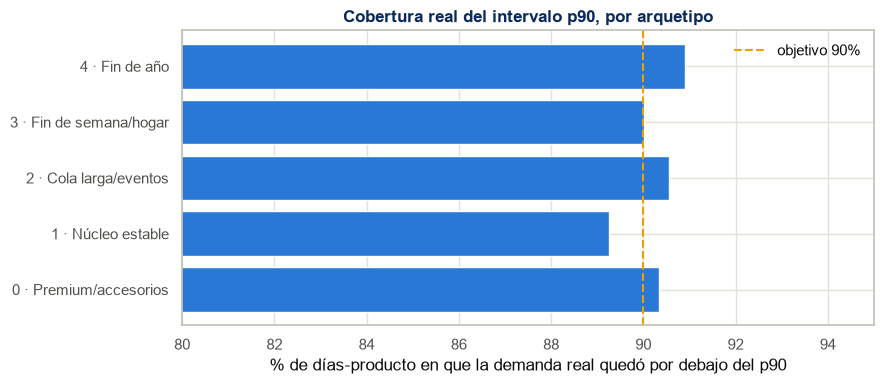

,cobertura_p90,stock_p90_vs_media
arquetipo,,
0 · Premium/accesorios,0.903,2.626
1 · Núcleo estable,0.893,2.088
2 · Cola larga/eventos,0.905,2.571
3 · Fin de semana/hogar,0.900,2.486
4 · Fin de año,0.909,2.502


In [30]:
cob_arq = []
for g in sorted(meta['cluster_k5'].unique()):
    k = (meta['cluster_k5'].values == g)
    vk = valido[k]
    cob_arq.append({'arquetipo': NOMBRES_ARQ[g], 'cobertura_p90': (y3[k][vk] <= q90[k][vk]).mean(),
                    'stock_p90_vs_media': q90[k][vk].sum() / max(media3[k][vk].sum(), 1)})
cob_arq = pd.DataFrame(cob_arq).set_index('arquetipo')

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cob_arq.index, cob_arq['cobertura_p90'] * 100, color=DSMARKET_BLUE)
ax.axvline(90, color=DSMARKET_GOLD, linestyle='--', linewidth=1.5, label='objetivo 90%')
ax.set_xlim(80, 95)
ax.set_title('Cobertura real del intervalo p90, por arquetipo', color=DSMARKET_NAVY, fontweight='bold')
ax.set_xlabel('% de días-producto en que la demanda real quedó por debajo del p90')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
cob_arq.round(3)

**Hallazgo — el modelo cuantílico está bien calibrado, y revela el costo real del nivel de servicio:**

La cobertura empírica del p90 es del **90,0%** contra un objetivo del 90%. Es una calibración casi exacta, y se mantiene pareja en los cinco arquetipos (entre 89,3% y 90,9%), lo cual importa: significa que el intervalo es confiable tanto para el núcleo estable como para la cola larga.

En pinball loss —la métrica propia de la regresión cuantílica— el modelo da **0,3097**, contra 0,5310 si usáramos la predicción media como si fuera un p90 y 0,3667 con el atajo casero de "media móvil × 2,5". O sea: el modelo cuantílico no solo es mejor que la media, también le gana a la heurística que un equipo de operaciones aplicaría a ojo.

**Y acá está el número que le interesa a Paul:**

- La predicción media cubre la demanda real solo el **67,8%** de las veces. Dicho de otro modo: **si se stockea según la predicción media, hay faltante en 1 de cada 3 combinaciones producto-día.**
- Para llegar al 90% de nivel de servicio hace falta **+127% de stock** (2.625.551 unidades contra 1.158.667 para las mismas cuatro semanas).

Ese salto no es un defecto del modelo, es la naturaleza del problema: cubrir la cola de una demanda muy asimétrica es caro. Pero ahora es una **decisión explícita y cuantificada** en vez de un número que alguien elige por intuición. Con los dos modelos se puede construir la curva completa de servicio contra capital inmovilizado, y es lo que la Tarea 4 necesita para justificar dónde poner el nivel de servicio en cada arquetipo — que no tiene por qué ser el mismo para el núcleo estable que para el premium.

## 12. Reconciliación jerárquica: la respuesta completa a Paul

En la sección 7 comparamos dos opciones y ganó bottom-up. Pero hay una tercera que no es "elegir uno de los dos": **combinar ambas fuentes de información de forma óptima**. Eso es la reconciliación jerárquica, y `MinT` (Minimum Trace) es su formulación estándar.

La idea: tenemos predicciones para cada nivel producidas de forma independiente, y esas predicciones son **incoherentes** — la de la ciudad no coincide exactamente con la suma de sus tiendas. MinT encuentra el ajuste que las hace coherentes minimizando la varianza total del error, dando más peso a las predicciones más confiables.

Armamos una jerarquía de **94 series**: 70 en la base (tienda × departamento) más 24 agregados (1 total, 3 ciudades, 10 tiendas, 7 departamentos y 3 grupos de comportamiento). Las predicciones base salen de LightGBM (abajo) y Prophet (arriba). La matriz de covarianza de los errores se estima con los residuos de los folds 1 y 2, y **se evalúa en el fold 3**, que no participó de esa estimación.

In [31]:
mint = pd.read_pickle(f"{CACHE}/mint_resultados.pkl")
piv_mint = mint.groupby(['nivel','metodo'])['MAPE_pct'].mean().unstack('metodo')
ORDEN_NIV = ['Total','Ciudad','Grupo','Tienda','Depto','base']
COLS = ['Base (Prophet arriba + bottom-up abajo)','Bottom-up puro','OLS (W = I)',
        'WLS (varianza por serie)','MinT (shrink)']
piv_mint.reindex(ORDEN_NIV)[COLS].round(2)

metodo,Base (Prophet arriba + bottom-up abajo),Bottom-up puro,OLS (W = I),WLS (varianza por serie),MinT (shrink)
nivel,,,,,
Total,5.37,4.67,5.36,4.97,4.55
Ciudad,7.06,5.97,7.00,6.15,5.60
Grupo,6.29,5.87,6.34,5.76,5.33
Tienda,7.48,7.14,7.34,6.70,6.26
Depto,9.46,10.29,9.22,8.89,8.64
base,17.68,17.68,25.63,16.34,16.12


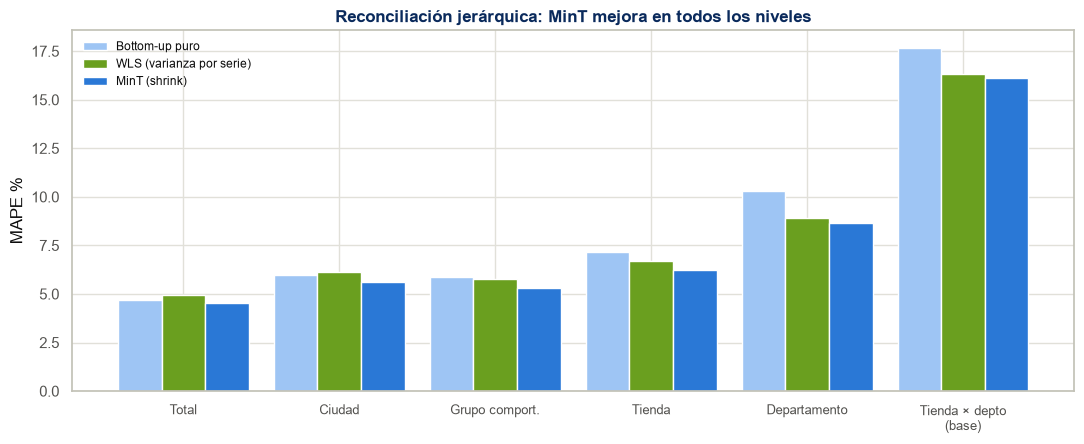

Mejora de MinT sobre bottom-up, por nivel (%):
nivel
Total      2.6
Ciudad     6.2
Grupo      9.2
Tienda    12.4
Depto     16.0
base       8.8

Promedio sobre todos los niveles: bottom-up 15.12% vs MinT 13.71%


In [32]:
fig, ax = plt.subplots(figsize=(11, 4.6))
etiquetas = {'Total':'Total','Ciudad':'Ciudad','Grupo':'Grupo comport.','Tienda':'Tienda',
             'Depto':'Departamento','base':'Tienda × depto\n(base)'}
x = np.arange(len(ORDEN_NIV)); ancho = 0.28
for i, (m, c) in enumerate([('Bottom-up puro', '#9ec5f4'), ('WLS (varianza por serie)', DSMARKET_GREEN),
                            ('MinT (shrink)', DSMARKET_BLUE)]):
    ax.bar(x + i*ancho, piv_mint.reindex(ORDEN_NIV)[m].values, ancho, label=m, color=c)
ax.set_xticks(x + ancho); ax.set_xticklabels([etiquetas[n] for n in ORDEN_NIV], fontsize=9)
ax.set_ylabel('MAPE %')
ax.set_title('Reconciliación jerárquica: MinT mejora en todos los niveles',
             color=DSMARKET_NAVY, fontweight='bold')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

mejora = ((piv_mint['Bottom-up puro'] - piv_mint['MinT (shrink)']) / piv_mint['Bottom-up puro'] * 100)
print("Mejora de MinT sobre bottom-up, por nivel (%):")
print(mejora.reindex(ORDEN_NIV).round(1).to_string())
print(f"\nPromedio sobre todos los niveles: bottom-up "
      f"{mint[mint['metodo']=='Bottom-up puro']['MAPE_pct'].mean():.2f}% vs MinT "
      f"{mint[mint['metodo']=='MinT (shrink)']['MAPE_pct'].mean():.2f}%")

**Hallazgo — MinT gana en los seis niveles, y además garantiza algo que ningún enfoque anterior daba:**

| Nivel | Bottom-up | WLS | **MinT (shrink)** | Mejora de MinT |
|---|---|---|---|---|
| Total compañía | 4,67% | 4,97% | **4,55%** | +2,6% |
| Ciudad | 5,97% | 6,15% | **5,60%** | +6,2% |
| Grupo de comportamiento | 5,87% | 5,76% | **5,33%** | +9,2% |
| Tienda | 7,14% | 6,70% | **6,26%** | +12,4% |
| Departamento | 10,29% | 8,89% | **8,64%** | +16,0% |
| Tienda × departamento (base) | 17,68% | 16,34% | **16,12%** | +8,8% |

*(MAPE, fold 3)*

En promedio, MinT baja el error del **15,12% al 13,71%**: un 9,3% de mejora relativa sobre el bottom-up, y sin entrenar un solo modelo nuevo — solo combinando mejor lo que ya teníamos. La mejora es más grande en los niveles intermedios (tienda y departamento), que es donde las dos fuentes de información se complementan más.

Vale la pena notar que **OLS es el peor de todos (21,04%)**: tratar todas las series por igual cuando el total de la compañía y una serie de tienda-departamento difieren en tres órdenes de magnitud destruye la reconciliación. La mayor parte de la ganancia ya aparece con WLS (ponderar por la varianza de cada serie); MinT la completa aprovechando además las correlaciones entre errores.

**Y hay un beneficio que no se ve en la tabla: la coherencia.** Las predicciones base son inconsistentes entre sí — el total que predice Prophet difiere hasta en **2.199 unidades** de la suma de las predicciones individuales para el mismo día. En la práctica eso significa que el número que ve el comité de dirección y el que usa el gerente de una tienda no cierran, y alguien tiene que explicar la diferencia. Todos los métodos reconciliados dan **incoherencia exactamente cero** por construcción.

**Cómo actualiza esto la respuesta a Paul:** su pregunta era binaria — ¿sumo o modelo cada nivel? La respuesta completa es que **no hace falta elegir**. Sumar es mejor que modelar cada nivel por separado (sección 7), pero reconciliar es mejor que sumar, y encima garantiza que todos los reportes cierren entre sí. Es el enfoque que recomendamos.

## 13. La entrega: predicción media y percentil 90

El paquete final para Paul y para el equipo de abastecimiento son dos archivos con la misma estructura (una fila por combinación tienda-producto, una columna por día del horizonte):

- **`predicciones_28dias.csv`** — la predicción central, para planificación y previsión de ventas.
- **`predicciones_28dias_p90.csv`** — el percentil 90, para dimensionar stock con nivel de servicio del 90%.

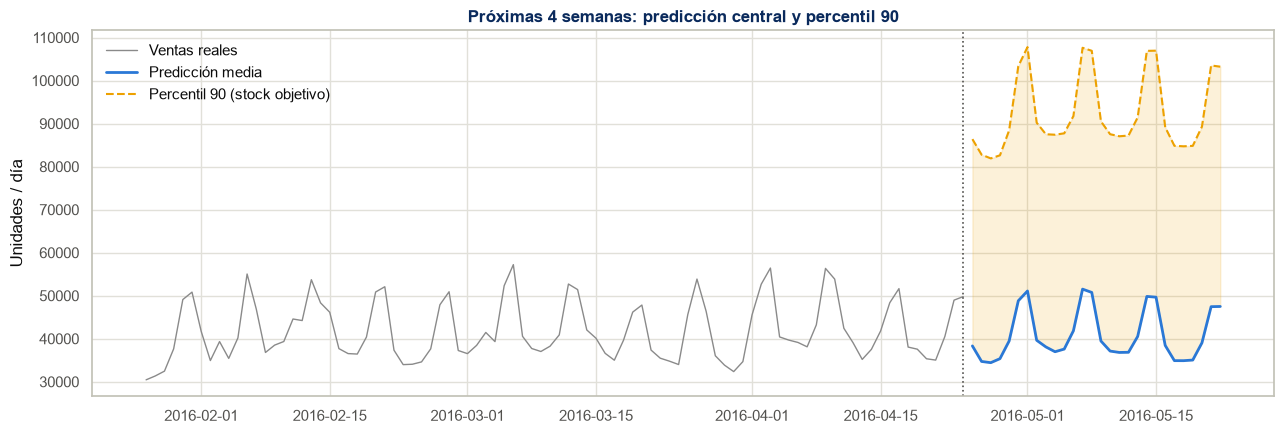

predicciones_28dias.csv: (30490, 29) | total 28 días: 1,146,189 unidades
predicciones_28dias_p90.csv: (30490, 29) | total 28 días: 2,589,559 unidades


In [33]:
pred_futuro = np.load(f"{CACHE}/pred_futuro.npy")
p90_futuro = np.load(f"{CACHE}/p90_final.npy")
fechas_fut = pd.date_range(cal['date'].max() + pd.Timedelta(days=1), periods=28)

fig, ax = plt.subplots(figsize=(13, 4.5))
hist_reciente = serie_total.iloc[-90:]
ax.plot(hist_reciente.index, hist_reciente.values, color='#8a8a8a', linewidth=1, label='Ventas reales')
ax.plot(fechas_fut, pred_futuro.sum(axis=0), color=DSMARKET_BLUE, linewidth=2, label='Predicción media')
ax.plot(fechas_fut, p90_futuro.sum(axis=0), color=DSMARKET_GOLD, linewidth=1.5, linestyle='--',
        label='Percentil 90 (stock objetivo)')
ax.fill_between(fechas_fut, pred_futuro.sum(axis=0), p90_futuro.sum(axis=0),
                color=DSMARKET_GOLD, alpha=0.15)
ax.axvline(cal['date'].max(), color='#52514e', linestyle=':', linewidth=1.2)
ax.set_title('Próximas 4 semanas: predicción central y percentil 90',
             color=DSMARKET_NAVY, fontweight='bold')
ax.set_ylabel('Unidades / día'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

for nombre, matriz in [('predicciones_28dias.csv', pred_futuro), ('predicciones_28dias_p90.csv', p90_futuro)]:
    salida = pd.DataFrame(matriz, columns=[f'F{i+1}' for i in range(28)])
    salida.insert(0, 'id', meta['id'].values)
    salida.to_csv(nombre, index=False, float_format='%.4f')
    print(f"{nombre}: {salida.shape} | total 28 días: {matriz.sum():,.0f} unidades")

## 14. Estado de la Tarea 3 y próximos pasos

**Lo que queda resuelto:**

| Pedido | Resultado |
|---|---|
| Predicción a 28 días por tienda-producto | LightGBM con bloques semanales, WRMSSE 1.0414. Entregado en `predicciones_28dias.csv`. |
| ¿Sirve sumar las predicciones para los agregados? | Sí — y reconciliar con **MinT** es todavía mejor (9,3% menos error que bottom-up) y garantiza que todos los niveles cierren entre sí. |
| Comparación de enfoques | Baselines, LightGBM, XGBoost, Prophet, SARIMA y cuatro esquemas de reconciliación, con validación walk-forward y cuatro métricas. |
| Incertidumbre para abastecimiento | Modelo cuantílico p90 con cobertura empírica del 90,0%, entregado en `predicciones_28dias_p90.csv`. |

**Las tres limitaciones que reportamos nosotros mismos:**

1. **Temporada alta.** En diciembre el error sube un 7% y la ventaja sobre una media móvil casi desaparece. Antes de usar esto para planificar fin de año hacen falta la regla de días de cierre (que ya cuantificamos: baja el WRMSSE de 1.1111 a 1.0805) y un tratamiento aparte de los productos estacionales.
2. **La cola larga no es predecible.** 4.840 series con RMSSE 1,29 — peor que el naive. No es un problema a resolver con más modelo, es un segmento que necesita otra política.
3. **El sesgo no es estable.** Se corrige recalculándolo en cada reentrenamiento con la ventana más reciente, nunca con un factor fijo.

**→ Lo que entra directo en la Tarea 4 (abastecimiento):**

- **Dos números por producto y día**, no uno: la predicción central para planificar y el p90 para dimensionar stock. Con ambos se construye la curva de nivel de servicio contra capital inmovilizado — pasar del 68% de servicio (stockear a la media) al 90% cuesta **+127% de inventario**.
- **Políticas distintas por arquetipo.** El núcleo estable (RMSSE 0,77, el 60% de las unidades) admite reposición basada en predicción con stock de seguridad ajustado. La cola larga (RMSSE 1,29) necesita punto de pedido y stock mínimo, sin predicción de por medio.
- **La regla de días de cierre** y la corrección del sesgo, que son ajustes de negocio y no de modelo.
- **Predicciones coherentes entre niveles** vía MinT: la compra centralizada y la reposición por tienda parten del mismo número.